# Modeling Human Activity States with a Hidden Markov Model

This notebook takes raw smartphone accelerometer + gyroscope recordings (Sensor Logger) and:

1. **Pre-processes** them: loads each recording, harmonises every phone to one sampling rate, trims start/stop handling noise and saves labelled CSVs to `data/processed/`.
2. **Extracts features**: time-domain and frequency-domain features from sliding windows.
3. **Defines and trains** a Gaussian-emission HMM implemented **from scratch in NumPy** (forward, backward, Viterbi, Baum-Welch).
4. **Visualises** the transition matrix, emission parameters and decoded activity sequences.
5. **Evaluates** on unseen recordings (sensitivity, specificity, accuracy per activity).
6. Runs small **experiments** on sampling rate and sensor noise to support the analysis section of the report.

Hidden states: `standing`, `walking`, `jumping`, `still`.

**Raw data layout:**

```
data/raw/train/<activity>/<recording>.zip    # training recordings (Sensor Logger zip, not unzipped)
data/raw/unseen/<activity>/<recording>.zip   # new session, never used for training
```

## 0. Setup and configuration

Fill in `PHONE` before running. If `data/raw/unseen/` is empty, the latest `HOLDOUT_FRACTION` of each activity's training recordings is held out as a temporary test set.

In [1]:
import os
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt

DATA_DIR = Path(os.environ.get("HAR_DATA_DIR", "data"))
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
OUT_DIR = Path(os.environ.get("HAR_OUT_DIR", "results"))
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ["standing", "walking", "jumping", "still"]
STATE_INDEX = {a: i for i, a in enumerate(ACTIVITIES)}

PARTICIPANT = "ibyishaka"
PHONE = "Samsung SM-A5260"
APP = "Sensor Logger"

TARGET_HZ = 50          # every recording is resampled to this rate
LOWPASS_HZ = 20         # common low-pass applied to every recording before resampling
TRIM_SECONDS = 0.5      # dropped from the start and end of each recording (tapping start/stop)
WINDOW_SECONDS = 2.0    # feature window length
STEP_SECONDS = 1.0      # hop between windows (50% overlap)
HOLDOUT_FRACTION = 0.2  # used only when data/raw/unseen is empty
FREQ_BANDS = ((0.3, 1.5), (1.5, 3.0), (3.0, 6.0))
EPS = 1e-6
G = 9.80665
SEED = 42

SENSOR_COLS = {"acc": ["acc_x", "acc_y", "acc_z"], "gyro": ["gyro_x", "gyro_y", "gyro_z"]}
ACC_COLS, GYRO_COLS = SENSOR_COLS["acc"], SENSOR_COLS["gyro"]

sns.set_theme(style="whitegrid")
np.set_printoptions(precision=3, suppress=True)
print("data:", DATA_DIR.resolve(), "| outputs:", OUT_DIR.resolve())

data: C:\Users\ibyis\OneDrive\Desktop\Coding\ALU-related\Formative2_ML_tech_2\data | outputs: C:\Users\ibyis\OneDrive\Desktop\Coding\ALU-related\Formative2_ML_tech_2\results


## 1. Data loading and pre-processing

Each recording is a **Sensor Logger** export `.zip`, read directly without unzipping. Only `Accelerometer.csv` (m/s²) and `Gyroscope.csv` (rad/s) are used; their columns are `time` (epoch nanoseconds), `seconds_elapsed`, `z`, `y`, `x`. The other files in the zip (Metadata, Gravity, Orientation, uncalibrated sensors, ...) are ignored. Unzipped export folders and single CSVs with both sensors (e.g. Physics Toolbox `gFx…`/`wx…`) are also accepted.

Pre-processing steps per recording:

1. Convert timestamps to seconds (and g-force to m/s² for Physics Toolbox files).
2. Keep only the span covered by **both** sensors and trim `TRIM_SECONDS` from each end.
3. **Harmonise the sampling rate.** Phones deliver irregular, device-specific rates, and the accelerometer and gyroscope are timestamped independently. Every recording gets the **same** 4th-order Butterworth low-pass at `LOWPASS_HZ` (which also acts as the anti-aliasing filter), then both sensors are linearly interpolated onto one shared `TARGET_HZ` grid. This aligns the two sensors, and using one filter for every rate stops the model from telling recordings apart by their noise floor instead of by the movement.
4. Save a labelled CSV `data/processed/<split>/<participant>_<activity>_<nn>.csv` with a `timestamp` column.

In [2]:
SENSOR_FILES = {"acc": "accelerometer", "gyro": "gyroscope"}
TIME_COLUMNS = ("time", "timestamp", "seconds_elapsed", "elapsed", "t")
ACC_ALIASES = [("acc_x", "acc_y", "acc_z"), ("ax", "ay", "az"), ("gfx", "gfy", "gfz"),
               ("accelerometer_x", "accelerometer_y", "accelerometer_z"), ("accel_x", "accel_y", "accel_z")]
GYRO_ALIASES = [("gyro_x", "gyro_y", "gyro_z"), ("wx", "wy", "wz"), ("gx", "gy", "gz"),
                ("gyroscope_x", "gyroscope_y", "gyroscope_z")]


def _norm(col):
    col = re.sub(r"\(.*?\)|\[.*?\]", "", str(col)).strip().lower()
    return re.sub(r"[^a-z0-9]+", "_", col).strip("_")


def _read_csv(src):
    df = pd.read_csv(src)
    df.columns = [_norm(c) for c in df.columns]
    return df


def _to_seconds(series):
    """Time column (epoch ns/us/ms/s, elapsed seconds, or datetime strings) -> float seconds."""
    if not pd.api.types.is_numeric_dtype(series):
        return pd.to_datetime(series).astype("int64").to_numpy() / 1e9
    t = series.to_numpy(dtype=float)
    med = np.nanmedian(np.abs(t))
    for threshold, scale in ((1e17, 1e9), (1e14, 1e6), (1e11, 1e3)):
        if med > threshold:
            return t / scale
    return t


def _time_seconds(df):
    for name in TIME_COLUMNS:
        if name in df.columns:
            return _to_seconds(df[name])
    raise ValueError(f"no time column in {list(df.columns)}")


def _xyz(df, aliases):
    for cols in aliases:
        if all(c in df.columns for c in cols):
            return df[list(cols)].to_numpy(dtype=float), cols
    return None, None


def _file_epoch(path):
    """Recording start parsed from a name like gForce_2026-10-28_09-26-05.csv (0 if absent)."""
    m = re.search(r"(\d{4}-\d{2}-\d{2})[_ T](\d{2})[-_:](\d{2})[-_:](\d{2})", path.name)
    return pd.Timestamp(f"{m[1]} {m[2]}:{m[3]}:{m[4]}").timestamp() if m else 0.0


def _sensor_tables(path):
    if path.suffix.lower() == ".zip":
        with zipfile.ZipFile(path) as zf:
            files = {Path(n).name.lower(): n for n in zf.namelist()}
            return {k: _read_csv(zf.open(files[f"{v}.csv"])) for k, v in SENSOR_FILES.items() if f"{v}.csv" in files}
    files = {p.name.lower(): p for p in path.iterdir()}
    return {k: _read_csv(files[f"{v}.csv"]) for k, v in SENSOR_FILES.items() if f"{v}.csv" in files}


def load_recording(path):
    """Return {'acc': (t, xyz in m/s²), 'gyro': (t, xyz in rad/s) or absent}, t in seconds."""
    path = Path(path)
    if path.is_file() and path.suffix.lower() == ".csv":
        df = _read_csv(path)
        t = _time_seconds(df)
        if np.nanmax(t) < 1e9:          # relative time (Physics Toolbox): anchor it to the file name
            t = t + _file_epoch(path)
        acc, acc_cols = _xyz(df, ACC_ALIASES)
        gyro, _ = _xyz(df, GYRO_ALIASES)
        if acc is None:
            raise ValueError(f"no accelerometer columns in {list(df.columns)}")
        if acc_cols[0] == "gfx":         # g-force is in g
            acc = acc * G
        return {"acc": (t, acc)} | ({"gyro": (t, gyro)} if gyro is not None else {})
    tables = _sensor_tables(path)
    if "acc" not in tables:
        raise ValueError("missing Accelerometer.csv")
    return {k: (_time_seconds(df), _xyz(df, [("x", "y", "z")])[0]) for k, df in tables.items()}


def discover(split):
    """List recordings under data/raw/<split>/<activity>/ (or data/raw/<split>/<participant>/<activity>/)."""
    split_dir = RAW_DIR / split
    if not split_dir.exists():
        return []
    groups = []
    for sub in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        if sub.name.lower() in STATE_INDEX:
            groups.append((PARTICIPANT, sub))
        else:
            groups += [(sub.name.lower(), d) for d in sorted(p for p in sub.iterdir() if p.is_dir())]
    recs = []
    for member, act_dir in groups:
        activity = act_dir.name.lower()
        if activity not in STATE_INDEX:
            warnings.warn(f"skipping unknown activity folder {act_dir}")
            continue
        for rec in sorted(act_dir.iterdir()):
            if rec.is_dir() or rec.suffix.lower() in (".zip", ".csv"):
                recs.append({"member": member, "activity": activity, "path": rec})
    return recs

In [3]:
def native_hz(t):
    dt = np.diff(np.sort(t))
    dt = dt[dt > 0]
    return 1.0 / np.median(dt)


def resample(t, xyz, grid):
    ok = np.isfinite(t) & np.isfinite(xyz).all(axis=1)
    t, xyz = t[ok], xyz[ok]
    t, idx = np.unique(t, return_index=True)   # sorts and drops duplicate timestamps
    xyz = xyz[idx]
    fs = native_hz(t)
    cutoff = min(LOWPASS_HZ, 0.45 * TARGET_HZ)
    if fs / 2 > 1.05 * cutoff and len(t) > 30:
        # same low-pass for every native rate (also the anti-aliasing filter for downsampling)
        b, a = butter(4, cutoff / (fs / 2))
        xyz = filtfilt(b, a, xyz, axis=0)
    return np.column_stack([np.interp(grid, t, xyz[:, i]) for i in range(3)]), fs


def preprocess(rec):
    sensors = load_recording(rec["path"])
    start = max(np.nanmin(t) for t, _ in sensors.values()) + TRIM_SECONDS
    end = min(np.nanmax(t) for t, _ in sensors.values()) - TRIM_SECONDS
    if end - start < WINDOW_SECONDS:
        raise ValueError(f"only {end - start:.1f}s left after trimming")
    grid = np.arange(start, end, 1.0 / TARGET_HZ)

    df = pd.DataFrame({"timestamp": grid, "t": grid - grid[0]})   # epoch seconds / seconds since start
    if grid[0] > 1e9:
        df.insert(1, "datetime", pd.to_datetime(grid, unit="s"))
    native = {}
    for name, (t, xyz) in sensors.items():
        resampled, native[name] = resample(t, xyz, grid)
        df[SENSOR_COLS[name]] = resampled
    df["activity"], df["member"] = rec["activity"], rec["member"]
    meta = {"member": rec["member"], "activity": rec["activity"], "source": str(rec["path"]),
            "start": grid[0], "duration_s": len(grid) / TARGET_HZ,
            "native_acc_hz": native["acc"], "native_gyro_hz": native.get("gyro", np.nan)}
    return df, meta


def build_split(split):
    frames, metas = [], []
    for rec in discover(split):
        try:
            df, meta = preprocess(rec)
        except Exception as exc:
            warnings.warn(f"skipping {rec['path']}: {exc}")
            continue
        frames.append(df)
        metas.append(meta)
    if not metas:
        return {}, pd.DataFrame()
    meta = pd.DataFrame(metas)
    # chronological order within each member, so concatenated sessions follow what was actually performed
    meta["order"] = range(len(meta))
    meta = meta.sort_values(["member", "start", "source"]).reset_index(drop=True)
    meta["nn"] = meta.groupby(["member", "activity"]).cumcount() + 1
    meta["recording_id"] = meta.member + "_" + meta.activity + "_" + meta.nn.map("{:02d}".format)
    meta["split"] = split
    data = {}
    for _, m in meta.iterrows():
        df = frames[m.order]
        df["recording_id"], df["split"] = m.recording_id, split
        data[m.recording_id] = df
    return data, meta.drop(columns=["order", "nn"])


def save_processed(data, meta, split):
    out = PROCESSED_DIR / split
    out.mkdir(parents=True, exist_ok=True)
    for old in out.glob("*.csv"):     # regenerate so removed raw files do not leave stale outputs
        old.unlink()
    for rid, df in data.items():
        df.to_csv(out / f"{rid}.csv", index=False)
    meta.to_csv(out / "_recordings.csv", index=False)

In [4]:
train_data, train_meta = build_split("train")
unseen_data, unseen_meta = build_split("unseen")
if not train_data:
    raise RuntimeError(f"No training recordings found under {RAW_DIR / 'train'} - see the README for the layout.")

HELD_OUT_FALLBACK = not unseen_data
if HELD_OUT_FALLBACK:
    warnings.warn(f"No data/raw/unseen recordings: holding out the latest {HOLDOUT_FRACTION:.0%} of each activity's "
                  "training recordings instead. Record a genuinely new session for the final report.")
    by_group = train_meta.groupby(["member", "activity"])
    newest_rank = by_group.cumcount(ascending=False)            # 0 = most recent recording
    size = by_group.recording_id.transform("size")
    n_hold = np.maximum(1, np.round(HOLDOUT_FRACTION * size)).astype(int)
    hold = train_meta.index[(newest_rank < n_hold) & (size > 1)]
    unseen_meta = train_meta.loc[hold].assign(split="unseen").reset_index(drop=True)
    train_meta = train_meta.drop(index=hold).reset_index(drop=True)
    unseen_data = {rid: train_data.pop(rid).assign(split="unseen") for rid in unseen_meta.recording_id}

processed = {**train_data, **unseen_data}
meta_all = pd.concat([train_meta, unseen_meta], ignore_index=True)
no_gyro = meta_all.loc[meta_all.native_gyro_hz.isna(), "source"].tolist()
USE_GYRO = not no_gyro
if not USE_GYRO:
    warnings.warn(f"{len(no_gyro)} recording(s) have no gyroscope, so the accelerometer only is used for ALL "
                  "recordings. Files without a gyroscope:\n  " + "\n  ".join(no_gyro[:10])
                  + ("\n  ..." if len(no_gyro) > 10 else ""))
    processed = {rid: df.drop(columns=GYRO_COLS, errors="ignore") for rid, df in processed.items()}
    train_data = {rid: processed[rid] for rid in train_data}
    unseen_data = {rid: processed[rid] for rid in unseen_data}
SENSORS = ["acc", "gyro"] if USE_GYRO else ["acc"]
SIGNAL_COLS = [c for s in SENSORS for c in SENSOR_COLS[s]]

save_processed(train_data, train_meta, "train")
save_processed(unseen_data, unseen_meta, "unseen")
meta = pd.concat([train_meta, unseen_meta], ignore_index=True)

print(f"{len(train_data)} training and {len(unseen_data)} unseen recordings; sensors used: {SENSORS}")
display(meta.pivot_table(index=["split", "member"], columns="activity", values="recording_id",
                         aggfunc="count", fill_value=0)[ACTIVITIES])

47 training and 36 unseen recordings; sensors used: ['acc', 'gyro']


,activity,standing,walking,jumping,still
split,member,,,,
train,ibyishaka,12,12,12,11
unseen,ibyishaka,9,9,9,9


### Sampling rate (copy these tables into the report)

`native_*_hz` is the rate the phone actually delivered, computed from the timestamps. Every recording was resampled to `TARGET_HZ`.

In [5]:
meta["native_acc_hz_rounded"] = meta.native_acc_hz.round()
rates = (meta.groupby("activity")
         .agg(recordings=("recording_id", "count"), native_acc_hz_median=("native_acc_hz", "median"),
              native_acc_hz_min=("native_acc_hz", "min"), native_acc_hz_max=("native_acc_hz", "max"),
              native_gyro_hz_median=("native_gyro_hz", "median"), mean_duration_s=("duration_s", "mean"))
         .reindex(ACTIVITIES).round(1))
rates["harmonised_hz"] = TARGET_HZ
rates.to_csv(OUT_DIR / "sampling_rates.csv")
print(f"Participant: {PARTICIPANT} | phone: {PHONE} | app: {APP} | sensors: {SENSORS}")
print("Recordings per native accelerometer rate (Hz):")
display(meta.groupby(["native_acc_hz_rounded", "activity"]).size().unstack(fill_value=0))
meta = meta.drop(columns="native_acc_hz_rounded")
if (meta.native_acc_hz < TARGET_HZ).any():
    warnings.warn("Some recordings are below TARGET_HZ - consider lowering TARGET_HZ to the slowest rate.")
rates

Participant: ibyishaka | phone: Samsung SM-A5260 | app: Sensor Logger | sensors: ['acc', 'gyro']
Recordings per native accelerometer rate (Hz):


activity,jumping,standing,still,walking
native_acc_hz_rounded,,,,
53.0,21,21,20,21


,recordings,native_acc_hz_median,native_acc_hz_min,native_acc_hz_max,native_gyro_hz_median,mean_duration_s,harmonised_hz
activity,,,,,,,
standing,21,52.9,52.9,52.9,52.9,7.9,50
walking,21,52.9,52.9,52.9,52.9,8.6,50
jumping,21,52.9,52.9,52.9,52.9,7.7,50
still,20,52.9,52.9,52.9,52.9,8.9,50


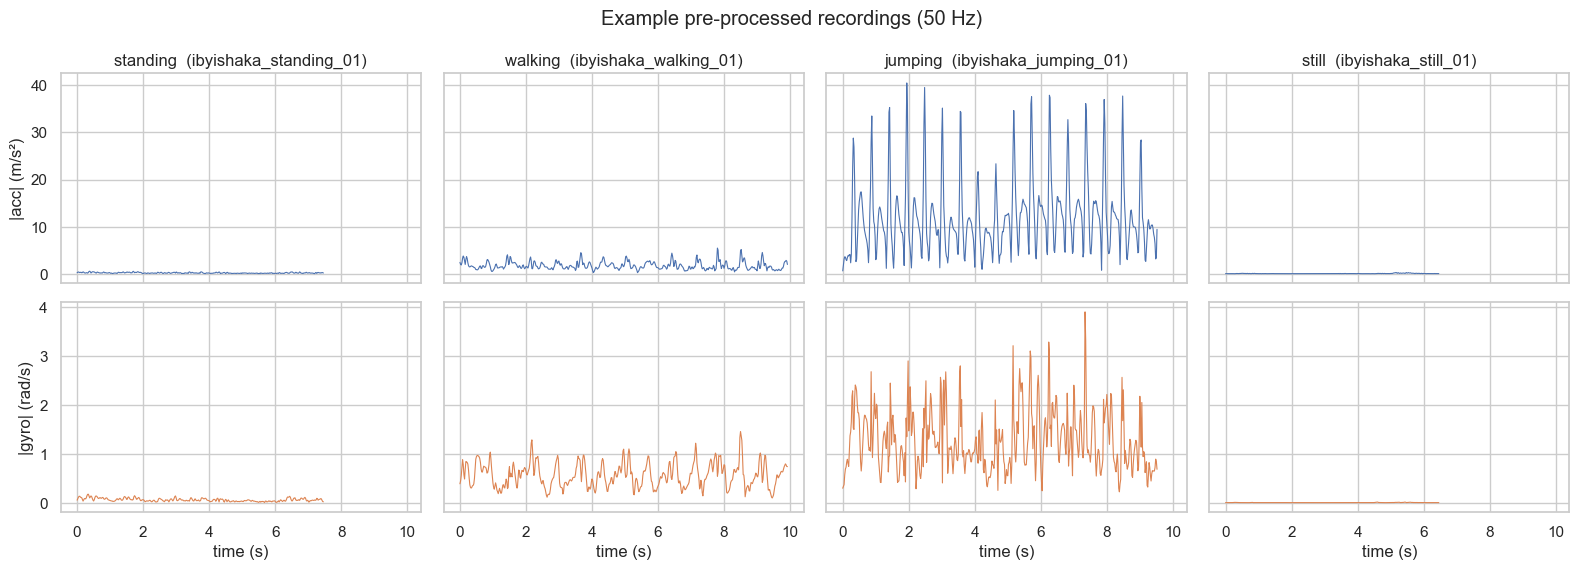

In [6]:
fig, axes = plt.subplots(len(SENSORS), len(ACTIVITIES), figsize=(16, 2.6 * len(SENSORS) + 0.6),
                         sharex=True, sharey="row", squeeze=False)
units = {"acc": "|acc| (m/s²)", "gyro": "|gyro| (rad/s)"}
for j, act in enumerate(ACTIVITIES):
    rid = train_meta[train_meta.activity == act].recording_id.iloc[0]
    df = processed[rid]
    for i, s in enumerate(SENSORS):
        axes[i, j].plot(df.t, np.linalg.norm(df[SENSOR_COLS[s]], axis=1), lw=0.8, color=f"C{i}")
        axes[i, 0].set_ylabel(units[s])
    axes[0, j].set_title(f"{act}  ({rid})")
    axes[-1, j].set_xlabel("time (s)")
fig.suptitle(f"Example pre-processed recordings ({TARGET_HZ} Hz)")
fig.tight_layout()
fig.savefig(FIG_DIR / "raw_signals.png", dpi=150)
plt.show()

## 2. Feature extraction

Each recording is cut into `WINDOW_SECONDS` windows with `STEP_SECONDS` hop. For each recorded sensor (accelerometer, plus the gyroscope when present) we compute:

| Domain | Features |
|---|---|
| Time | per-axis mean, per-axis std (log), magnitude mean, magnitude variance (log), signal magnitude area SMA (log), correlation between axes (xy, xz, yz) |
| Frequency (FFT of the de-meaned, Hann-windowed magnitude) | dominant frequency, total spectral energy (log), fraction of energy in the 0.3-1.5 / 1.5-3 / 3-6 Hz bands |

Scale features (std, variance, SMA, energy) are log-transformed because they span orders of magnitude between *still* and *jumping*, and their logs are much closer to Gaussian, which is what the HMM's emission model assumes. All features are then z-scored using **training-set** statistics only. The resulting sequence of feature vectors is the HMM's observation sequence **X**.

In [7]:
def safe_corr(a, b):
    sa, sb = a.std(), b.std()
    if sa < 1e-9 or sb < 1e-9:
        return 0.0
    return float(np.mean((a - a.mean()) * (b - b.mean())) / (sa * sb))


def window_features(signals, fs):
    """signals: {sensor name: (n, 3) array} for one window."""
    feats = {}
    n = len(next(iter(signals.values())))
    freqs = np.fft.rfftfreq(n, 1 / fs)
    taper = np.hanning(n)
    for name, sig in signals.items():
        mag = np.linalg.norm(sig, axis=1)
        for i, ax in enumerate("xyz"):
            feats[f"{name}_mean_{ax}"] = sig[:, i].mean()
            feats[f"{name}_logstd_{ax}"] = np.log10(sig[:, i].std() + EPS)
        feats[f"{name}_mag_mean"] = mag.mean()
        feats[f"{name}_mag_logvar"] = np.log10(mag.var() + EPS)
        feats[f"{name}_logsma"] = np.log10(np.abs(sig).sum(axis=1).mean() + EPS)
        for a, b in ((0, 1), (0, 2), (1, 2)):
            feats[f"{name}_corr_{'xyz'[a]}{'xyz'[b]}"] = safe_corr(sig[:, a], sig[:, b])
        power = np.abs(np.fft.rfft((mag - mag.mean()) * taper)) ** 2 / n
        power[0] = 0.0
        total = power.sum()
        feats[f"{name}_dom_freq"] = freqs[np.argmax(power)] if total > 0 else 0.0
        feats[f"{name}_log_spec_energy"] = np.log10(total + EPS)
        for lo, hi in FREQ_BANDS:
            band = (freqs >= lo) & (freqs < hi)
            feats[f"{name}_band_{lo:g}_{hi:g}hz"] = power[band].sum() / (total + EPS)
    return feats


def extract_windows(frames, meta, fs):
    win, step = int(round(WINDOW_SECONDS * fs)), int(round(STEP_SECONDS * fs))
    rows = []
    for order, m in enumerate(meta.itertuples()):
        df = frames[m.recording_id]
        signals = {name: df[SENSOR_COLS[name]].to_numpy() for name in SENSORS}
        for w, s in enumerate(range(0, len(df) - win + 1, step)):
            rows.append({"recording_id": m.recording_id, "member": m.member, "activity": m.activity,
                         "split": m.split, "rec_order": order, "window_idx": w,
                         **window_features({k: v[s:s + win] for k, v in signals.items()}, fs)})
    out = pd.DataFrame(rows)
    out["state"] = out.activity.map(STATE_INDEX)
    return out


META_COLS = ["recording_id", "member", "activity", "split", "rec_order", "window_idx", "state"]
windows = extract_windows(processed, meta, TARGET_HZ)
FEATURES = [c for c in windows.columns if c not in META_COLS]
windows.to_csv(OUT_DIR / "window_features.csv", index=False)
print(f"{len(windows)} windows x {len(FEATURES)} features")
windows.groupby(["split", "activity"]).size().unstack()[ACTIVITIES]

511 windows x 34 features


activity,standing,walking,jumping,still
split,,,,
train,69,82,75,63
unseen,52,60,57,53


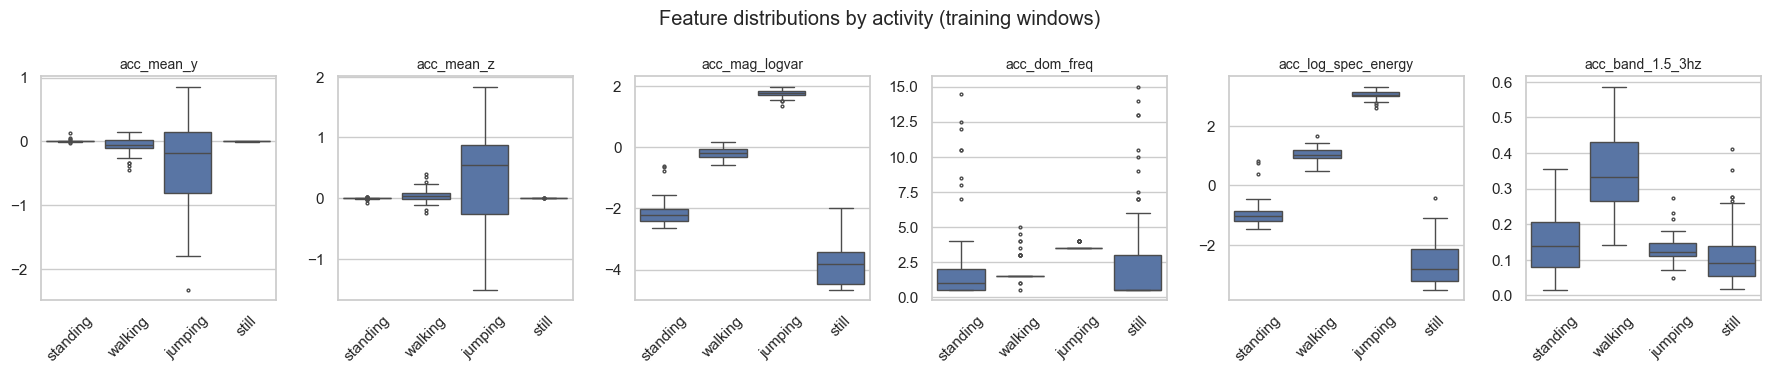

In [8]:
key_features = [f for f in ["acc_mean_y", "acc_mean_z", "acc_mag_logvar", "acc_dom_freq", "acc_log_spec_energy",
                            "acc_band_1.5_3hz", "gyro_logsma", "gyro_dom_freq"] if f in FEATURES][:6]
fig, axes = plt.subplots(1, len(key_features), figsize=(18, 3.8))
train_windows = windows[windows.split == "train"]
for ax, f in zip(axes, key_features):
    sns.boxplot(data=train_windows, x="activity", y=f, order=ACTIVITIES, ax=ax, fliersize=2)
    ax.set_title(f, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Feature distributions by activity (training windows)")
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_distributions.png", dpi=150)
plt.show()

In [9]:
def fit_scaler(df):
    mu = df[FEATURES].mean()
    sd = df[FEATURES].std(ddof=0).replace(0, 1.0)
    return mu, sd


def build_sequences(df, split, mu, sd):
    """One observation sequence per member: their recordings concatenated in the order they were recorded."""
    seqs = []
    for member, g in df[df.split == split].groupby("member", sort=True):
        g = g.sort_values(["rec_order", "window_idx"])
        seqs.append({"member": member, "X": ((g[FEATURES] - mu) / sd).to_numpy(),
                     "y": g.state.to_numpy(), "recording_id": g.recording_id.to_numpy()})
    return seqs


mu, sd = fit_scaler(windows[windows.split == "train"])
train_seqs = build_sequences(windows, "train", mu, sd)
unseen_seqs = build_sequences(windows, "unseen", mu, sd)
print("train sequences:", [(s["member"], len(s["y"])) for s in train_seqs])
print("unseen sequences:", [(s["member"], len(s["y"])) for s in unseen_seqs])

train sequences: [('ibyishaka', 289)]
unseen sequences: [('ibyishaka', 222)]


## 3. HMM components

| Element | In this project |
|---|---|
| **Hidden states Z** | 4 activities: standing, walking, jumping, still |
| **Observations X** | the z-scored feature vector of each 2 s window (one observation per second) |
| **Transition matrix A** | `A[i, j] = P(z_t = j | z_{t-1} = i)`. Estimated by counting consecutive-window label pairs in each member's session (recordings concatenated in recording order), with Laplace smoothing so no transition is impossible |
| **Emission model B** | `P(x_t | z_t = k)` = multivariate Gaussian with diagonal covariance, mean `μ_k`, variance `σ²_k` per feature |
| **Initial distribution π** | `π_k = P(z_1 = k)`, from the first window of each session, Laplace-smoothed |

**Algorithm choice (brief).**

* **Training: supervised maximum likelihood.** Our windows are labelled, so π, A and the Gaussian parameters have closed-form MLE estimates (counts and per-state means/variances). This is exact and cannot "swap" state meanings.
* **Baum-Welch (EM, forward-backward)** is the right tool when labels are missing or noisy. Here it is used only as a refinement experiment. EM maximises *likelihood*, not *accuracy*, so we keep it only if it does not hurt sensitivity/specificity.
* **Decoding: Viterbi.** It returns the single most probable *sequence* of activities. Using A, it suppresses one-window flickers (e.g. *walking-jumping-walking*), which raises sensitivity on long, continuous activities. **Posterior (forward-backward) decoding** picks the most probable state per window, which maximises *expected per-window accuracy*. We report both, together with a no-transition baseline, to show what the temporal model adds.
* **Forward algorithm** gives log P(X | model). We use it to monitor training and to compare how well the model fits training vs. unseen data (generalisation).

All computations are done in log space for numerical stability.

In [10]:
def logsumexp(a, axis=None, keepdims=False):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return out if keepdims else np.squeeze(out, axis=axis)


class GaussianHMM:
    """HMM with diagonal-covariance Gaussian emissions, implemented with NumPy only."""

    def __init__(self, n_states, state_names=None, var_floor=1e-3):
        self.K = n_states
        self.state_names = state_names or [str(k) for k in range(n_states)]
        self.var_floor = var_floor

    # ---------- parameter estimation ----------
    def fit_supervised(self, sequences, alpha=1.0):
        """Closed-form MLE from labelled sequences [(X, y), ...] with Laplace smoothing `alpha`."""
        X_all = np.vstack([X for X, _ in sequences])
        y_all = np.concatenate([y for _, y in sequences])
        missing = [self.state_names[k] for k in range(self.K) if not np.any(y_all == k)]
        if missing:
            raise ValueError(f"no training windows for states {missing}")
        self.means = np.array([X_all[y_all == k].mean(axis=0) for k in range(self.K)])
        self.vars = np.maximum(np.array([X_all[y_all == k].var(axis=0) for k in range(self.K)]), self.var_floor)
        starts = np.full(self.K, alpha)
        trans = np.full((self.K, self.K), alpha)
        for _, y in sequences:
            starts[y[0]] += 1
            np.add.at(trans, (y[:-1], y[1:]), 1)
        self.pi = starts / starts.sum()
        self.A = trans / trans.sum(axis=1, keepdims=True)
        return self

    def baum_welch(self, sequences, n_iter=50, tol=1e-4, pseudocount=1.0):
        """Unsupervised EM refinement of pi, A and the Gaussians. Returns the log-likelihood history."""
        history = []
        for _ in range(n_iter):
            start_acc = np.full(self.K, pseudocount)
            trans_acc = np.full((self.K, self.K), pseudocount)
            g_sum = np.zeros(self.K)
            x_sum = np.zeros_like(self.means)
            x2_sum = np.zeros_like(self.means)
            total_ll = 0.0
            logA = np.log(self.A)
            for X in sequences:
                logB = self.log_emission(X)
                la, ll = self.forward(X, logB)
                lb = self.backward(X, logB)
                gamma = np.exp(la + lb - ll)
                if len(X) > 1:
                    log_xi = la[:-1, :, None] + logA[None] + logB[1:, None, :] + lb[1:, None, :] - ll
                    trans_acc += np.exp(logsumexp(log_xi, axis=0))
                start_acc += gamma[0]
                g_sum += gamma.sum(axis=0)
                x_sum += gamma.T @ X
                x2_sum += gamma.T @ X ** 2
                total_ll += ll
            history.append(total_ll)
            self.pi = start_acc / start_acc.sum()
            self.A = trans_acc / trans_acc.sum(axis=1, keepdims=True)
            denom = np.maximum(g_sum, EPS)[:, None]
            self.means = x_sum / denom
            self.vars = np.maximum(x2_sum / denom - self.means ** 2, self.var_floor)
            if len(history) > 1 and abs(history[-1] - history[-2]) < tol * abs(history[-2]):
                break
        return history

    # ---------- inference ----------
    def log_emission(self, X):
        diff = X[:, None, :] - self.means[None]
        return -0.5 * (np.sum(np.log(2 * np.pi * self.vars), axis=1)[None]
                       + np.sum(diff ** 2 / self.vars[None], axis=2))

    def forward(self, X, logB=None):
        logB = self.log_emission(X) if logB is None else logB
        logA = np.log(self.A)
        la = np.empty((len(X), self.K))
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, len(X)):
            la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
        return la, logsumexp(la[-1])

    def backward(self, X, logB=None):
        logB = self.log_emission(X) if logB is None else logB
        logA = np.log(self.A)
        lb = np.zeros((len(X), self.K))
        for t in range(len(X) - 2, -1, -1):
            lb[t] = logsumexp(logA + logB[t + 1][None] + lb[t + 1][None], axis=1)
        return lb

    def posteriors(self, X):
        logB = self.log_emission(X)
        la, ll = self.forward(X, logB)
        return np.exp(la + self.backward(X, logB) - ll)

    def viterbi(self, X):
        logB = self.log_emission(X)
        logA = np.log(self.A)
        T = len(X)
        psi = np.zeros((T, self.K), dtype=int)
        delta = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[:, None] + logA
            psi[t] = scores.argmax(axis=0)
            delta = scores.max(axis=0) + logB[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta.argmax()
        for t in range(T - 1, 0, -1):
            path[t - 1] = psi[t, path[t]]
        return path, delta.max()

    def score(self, X):
        return self.forward(X)[1]

    def copy(self):
        new = GaussianHMM(self.K, self.state_names, self.var_floor)
        new.pi, new.A, new.means, new.vars = self.pi.copy(), self.A.copy(), self.means.copy(), self.vars.copy()
        return new

### Sanity check on a known model

Before using real data we check the implementation: sample from a hand-made 2-state HMM, verify that the forward and backward passes give the same likelihood, and that Viterbi recovers most of the hidden path.

In [11]:
def sample_hmm(model, T, rng):
    z = np.empty(T, dtype=int)
    z[0] = rng.choice(model.K, p=model.pi)
    for t in range(1, T):
        z[t] = rng.choice(model.K, p=model.A[z[t - 1]])
    X = model.means[z] + rng.standard_normal((T, model.means.shape[1])) * np.sqrt(model.vars[z])
    return X, z


toy = GaussianHMM(2)
toy.pi, toy.A = np.array([0.5, 0.5]), np.array([[0.95, 0.05], [0.1, 0.9]])
toy.means, toy.vars = np.array([[0.0, 0.0], [1.5, -1.0]]), np.ones((2, 2))
Xs, zs = sample_hmm(toy, 500, np.random.default_rng(SEED))
la, ll = toy.forward(Xs)
lb = toy.backward(Xs)
ll_backward = logsumexp(np.log(toy.pi) + toy.log_emission(Xs)[0] + lb[0])
assert np.isclose(ll, ll_backward), (ll, ll_backward)
assert np.allclose(toy.posteriors(Xs).sum(axis=1), 1.0)
toy_path, _ = toy.viterbi(Xs)
print(f"forward LL = {ll:.2f}, backward LL = {ll_backward:.2f}, Viterbi path accuracy = {(toy_path == zs).mean():.3f}")

forward LL = -1512.25, backward LL = -1512.25, Viterbi path accuracy = 0.954


## 4. Training

In [12]:
labelled_train = [(s["X"], s["y"]) for s in train_seqs]
hmm = GaussianHMM(len(ACTIVITIES), ACTIVITIES).fit_supervised(labelled_train)

# Baum-Welch refinement experiment, initialised from the supervised estimates
hmm_bw = hmm.copy()
bw_history = hmm_bw.baum_welch([s["X"] for s in train_seqs], n_iter=50)

# Baseline without temporal structure: uniform pi and A, so decoding = per-window Gaussian classifier
hmm_static = hmm.copy()
hmm_static.pi = np.full(hmm.K, 1 / hmm.K)
hmm_static.A = np.full((hmm.K, hmm.K), 1 / hmm.K)

print("pi =", hmm.pi)
pd.DataFrame(hmm.A, index=ACTIVITIES, columns=ACTIVITIES).round(3)

pi = [0.2 0.2 0.2 0.4]


,standing,walking,jumping,still
standing,0.932,0.014,0.027,0.027
walking,0.035,0.942,0.012,0.012
jumping,0.013,0.013,0.949,0.026
still,0.015,0.045,0.030,0.910


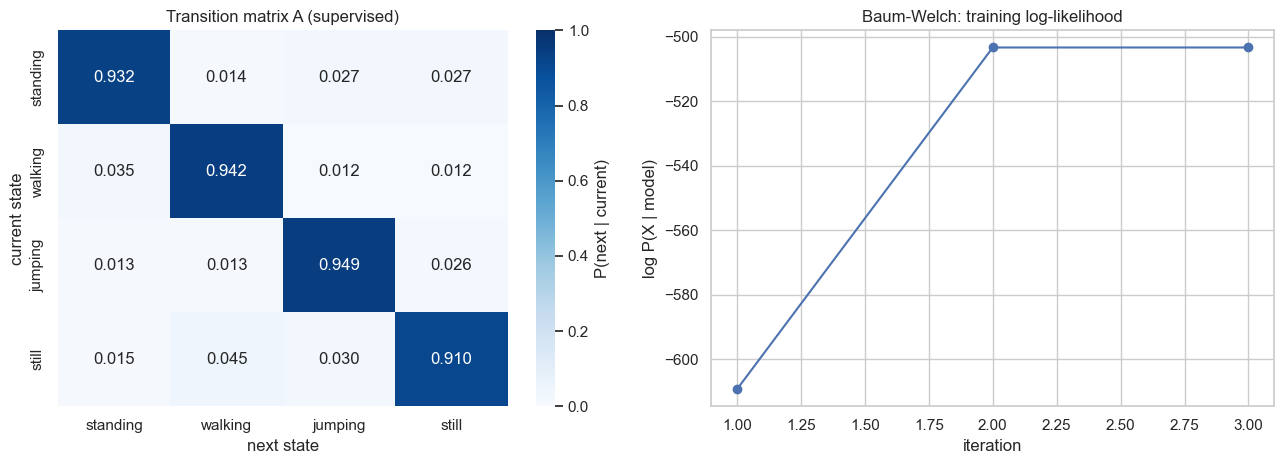

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(pd.DataFrame(hmm.A, index=ACTIVITIES, columns=ACTIVITIES), annot=True, fmt=".3f",
            cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "P(next | current)"})
axes[0].set_title("Transition matrix A (supervised)")
axes[0].set_xlabel("next state")
axes[0].set_ylabel("current state")
axes[1].plot(range(1, len(bw_history) + 1), bw_history, marker="o")
axes[1].set_title("Baum-Welch: training log-likelihood")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("log P(X | model)")
axes[1].ticklabel_format(useOffset=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "transition_matrix.png", dpi=150)
plt.show()

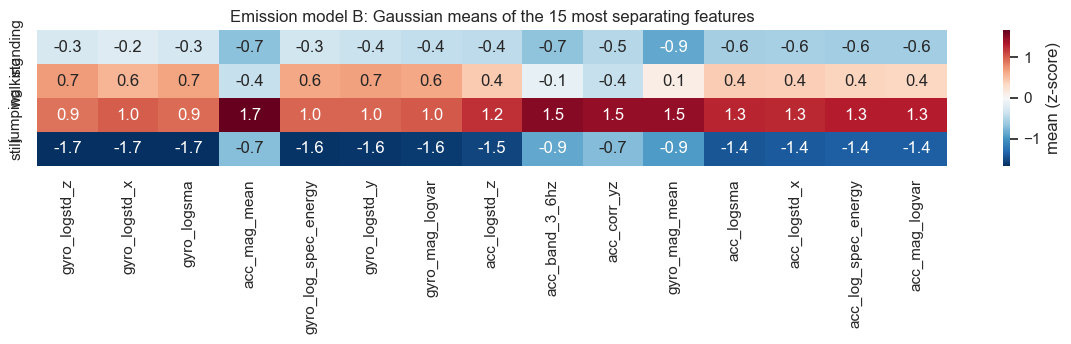

In [14]:
top = pd.Series(np.abs(hmm.means).max(axis=0), index=FEATURES).sort_values(ascending=False).index[:15]
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(pd.DataFrame(hmm.means, index=ACTIVITIES, columns=FEATURES)[top], annot=True, fmt=".1f",
            cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "mean (z-score)"})
ax.set_title("Emission model B: Gaussian means of the 15 most separating features")
fig.tight_layout()
fig.savefig(FIG_DIR / "emission_means.png", dpi=150)
plt.show()

## 5. Evaluation on unseen data

In [15]:
def decode(model, seqs, method="viterbi"):
    if method == "viterbi":
        return [model.viterbi(s["X"])[0] for s in seqs]
    return [model.posteriors(s["X"]).argmax(axis=1) for s in seqs]


def metrics_table(y_true, y_pred, seqs):
    rec_counts = pd.Series(np.concatenate([s["recording_id"] for s in seqs])).drop_duplicates()
    rec_counts = rec_counts.str.extract(r"_(" + "|".join(ACTIVITIES) + r")_\d+$")[0].value_counts()
    acc = np.mean(y_true == y_pred)
    rows = []
    for k, name in enumerate(ACTIVITIES):
        tp = np.sum((y_pred == k) & (y_true == k))
        fn = np.sum((y_pred != k) & (y_true == k))
        fp = np.sum((y_pred == k) & (y_true != k))
        tn = len(y_true) - tp - fn - fp
        rows.append({"State (Activity)": name,
                     "Recordings": int(rec_counts.get(name, 0)),
                     "Number of Samples (windows)": int(tp + fn),
                     "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                     "Specificity": tn / (tn + fp) if tn + fp else np.nan,
                     "Overall Accuracy": acc})
    return pd.DataFrame(rows)


def to_markdown(df, digits=3):
    cells = [[f"{v:.{digits}f}" if isinstance(v, float) else str(v) for v in row] for row in df.itertuples(index=False)]
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    return "\n".join(lines + ["| " + " | ".join(r) + " |" for r in cells])


y_unseen = np.concatenate([s["y"] for s in unseen_seqs])
y_train = np.concatenate([s["y"] for s in train_seqs])
candidates = {
    "HMM supervised + Viterbi": (hmm, "viterbi"),
    "HMM supervised + posterior": (hmm, "posterior"),
    "HMM Baum-Welch + Viterbi": (hmm_bw, "viterbi"),
    "No transitions (per-window Gaussian)": (hmm_static, "viterbi"),
}
comparison = []
for name, (model, method) in candidates.items():
    comparison.append({"model": name,
                       "train accuracy": np.mean(np.concatenate(decode(model, train_seqs, method)) == y_train),
                       "unseen accuracy": np.mean(np.concatenate(decode(model, unseen_seqs, method)) == y_unseen)})
comparison = pd.DataFrame(comparison).set_index("model")
comparison.round(3)

,train accuracy,unseen accuracy
model,,
HMM supervised + Viterbi,0.997,1.0
HMM supervised + posterior,0.997,1.0
HMM Baum-Welch + Viterbi,0.997,1.0
No transitions (per-window Gaussian),0.997,1.0


### Evaluation table (main model: supervised HMM + Viterbi)

"Number of Samples" counts 2 s windows; "Recordings" counts recorded files. Sensitivity = TP / (TP + FN), specificity = TN / (TN + FP), computed one-vs-rest per activity. Overall accuracy is the fraction of all unseen windows decoded correctly. The table is also saved to `results/evaluation_table.md` so it can be pasted straight into the report.

In [16]:
FINAL_MODEL, FINAL_METHOD = hmm, "viterbi"
pred_seqs = decode(FINAL_MODEL, unseen_seqs, FINAL_METHOD)
y_pred = np.concatenate(pred_seqs)
eval_table = metrics_table(y_unseen, y_pred, unseen_seqs)
(OUT_DIR / "evaluation_table.md").write_text(to_markdown(eval_table) + "\n")
eval_table.round(3)

,State (Activity),Recordings,Number of Samples (windows),Sensitivity,Specificity,Overall Accuracy
0,standing,9,52,1.0,1.0,1.0
1,walking,9,60,1.0,1.0,1.0
2,jumping,9,57,1.0,1.0,1.0
3,still,9,53,1.0,1.0,1.0


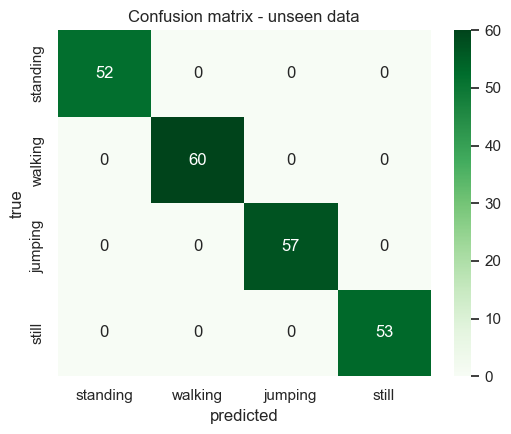

In [17]:
cm = pd.crosstab(pd.Categorical(np.array(ACTIVITIES)[y_unseen], ACTIVITIES),
                 pd.Categorical(np.array(ACTIVITIES)[y_pred], ACTIVITIES), dropna=False)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=ax)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Confusion matrix - unseen data")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150)
plt.show()

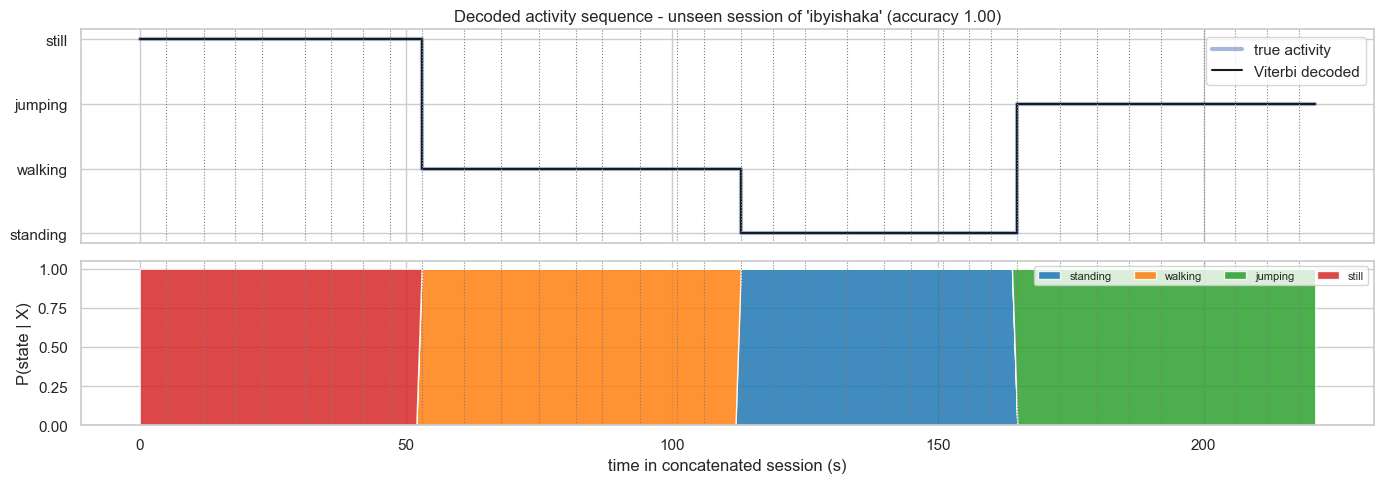

In [18]:
palette = dict(zip(ACTIVITIES, sns.color_palette("tab10", len(ACTIVITIES))))
for s, path in zip(unseen_seqs, pred_seqs):
    t = np.arange(len(s["y"])) * STEP_SECONDS
    post = FINAL_MODEL.posteriors(s["X"])
    bounds = t[1:][s["recording_id"][1:] != s["recording_id"][:-1]]
    fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
    axes[0].step(t, s["y"], where="post", lw=3, alpha=0.5, label="true activity")
    axes[0].step(t, path, where="post", lw=1.5, color="k", label="Viterbi decoded")
    axes[0].set_yticks(range(len(ACTIVITIES)), ACTIVITIES)
    axes[0].legend(loc="upper right")
    axes[0].set_title(f"Decoded activity sequence - unseen session of '{s['member']}' "
                      f"(accuracy {np.mean(path == s['y']):.2f})")
    axes[1].stackplot(t, post.T, labels=ACTIVITIES, colors=[palette[a] for a in ACTIVITIES], alpha=0.85)
    axes[1].set_ylabel("P(state | X)")
    axes[1].set_xlabel("time in concatenated session (s)")
    axes[1].legend(loc="upper right", ncol=4, fontsize=8)
    for ax in axes:
        for b in bounds:
            ax.axvline(b, color="grey", ls=":", lw=0.8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"decoded_sequence_{s['member']}.png", dpi=150)
    plt.show()

### Generalisation

We compare accuracy and the average log-likelihood per window (forward algorithm) on training vs. unseen data. A large drop in either signals that the unseen recordings differ from the training distribution (new phone placement, environment or participant).

In [19]:
gen = pd.DataFrame([
    {"data": "train", "windows": len(y_train),
     "accuracy": np.mean(np.concatenate(decode(FINAL_MODEL, train_seqs, FINAL_METHOD)) == y_train),
     "log-likelihood / window": sum(FINAL_MODEL.score(s["X"]) for s in train_seqs) / len(y_train)},
    {"data": "unseen", "windows": len(y_unseen), "accuracy": np.mean(y_pred == y_unseen),
     "log-likelihood / window": sum(FINAL_MODEL.score(s["X"]) for s in unseen_seqs) / len(y_unseen)},
]).set_index("data")
per_member = pd.DataFrame([{"member": s["member"], "windows": len(s["y"]), "accuracy": np.mean(p == s["y"])}
                           for s, p in zip(unseen_seqs, pred_seqs)]).set_index("member")
if HELD_OUT_FALLBACK:
    print("WARNING: 'unseen' = held-out recordings from the training sessions, not a new session.")
display(gen.round(3))
per_member.round(3)

,windows,accuracy,log-likelihood / window
data,,,
train,289,0.997,-2.108
unseen,222,1.000,-0.691


,windows,accuracy
member,,
ibyishaka,222,1.0


## 6. Experiments for the analysis

**Sampling rate.** Re-run the whole pipeline after downsampling every recording to lower rates.
**Sensor noise.** Add Gaussian noise (as a fraction of each channel's standard deviation in the training data) to the *unseen* recordings only, and decode with the model trained on clean data.

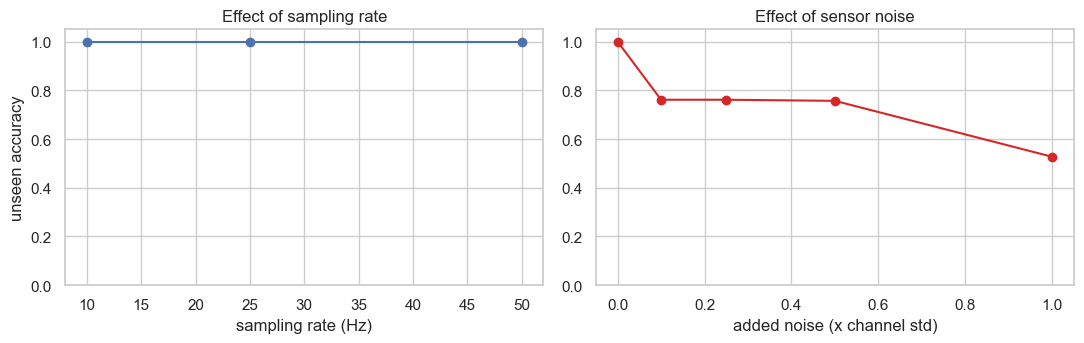

,sampling rate (Hz),unseen accuracy
0,50.0,1.0
1,25.0,1.0
2,10.0,1.0


,noise (x channel std),unseen accuracy
0,0.00,1.000
1,0.10,0.761
2,0.25,0.761
3,0.50,0.757
4,1.00,0.527


In [20]:
def downsample(df, fs_from, fs_to):
    k = int(round(fs_from / fs_to))
    if k <= 1:
        return df
    b, a = butter(4, 0.8 / k)
    out = df.iloc[::k].copy()
    out[SIGNAL_COLS] = filtfilt(b, a, df[SIGNAL_COLS].to_numpy(), axis=0)[::k]
    return out


def run_pipeline(frames, fs):
    w = extract_windows(frames, meta, fs)
    m, s = fit_scaler(w[w.split == "train"])
    tr, te = build_sequences(w, "train", m, s), build_sequences(w, "unseen", m, s)
    model = GaussianHMM(len(ACTIVITIES), ACTIVITIES).fit_supervised([(q["X"], q["y"]) for q in tr])
    y_true = np.concatenate([q["y"] for q in te])
    return np.mean(np.concatenate(decode(model, te)) == y_true)


rate_results = []
for fs in (50, 25, 10):
    fs_eff = TARGET_HZ / round(TARGET_HZ / fs)
    frames = {rid: downsample(df, TARGET_HZ, fs) for rid, df in processed.items()}
    rate_results.append({"sampling rate (Hz)": fs_eff, "unseen accuracy": run_pipeline(frames, fs_eff)})
rate_results = pd.DataFrame(rate_results)

rng = np.random.default_rng(SEED)
channel_sd = pd.concat([processed[r] for r in train_meta.recording_id])[SIGNAL_COLS].std().to_numpy()
noise_results = []
for level in (0.0, 0.1, 0.25, 0.5, 1.0):
    frames = {rid: (df.assign(**dict(zip(SIGNAL_COLS, (df[SIGNAL_COLS].to_numpy()
                                                          + rng.standard_normal((len(df), len(SIGNAL_COLS))) * channel_sd * level).T)))
                    if df.split.iloc[0] == "unseen" else df)
              for rid, df in processed.items()}
    noise_results.append({"noise (x channel std)": level, "unseen accuracy": run_pipeline(frames, TARGET_HZ)})
noise_results = pd.DataFrame(noise_results)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(rate_results.iloc[:, 0], rate_results.iloc[:, 1], marker="o")
axes[0].set_xlabel("sampling rate (Hz)")
axes[0].set_ylabel("unseen accuracy")
axes[0].set_title("Effect of sampling rate")
axes[1].plot(noise_results.iloc[:, 0], noise_results.iloc[:, 1], marker="o", color="tab:red")
axes[1].set_xlabel("added noise (x channel std)")
axes[1].set_title("Effect of sensor noise")
for ax in axes:
    ax.set_ylim(0, 1.05)
fig.tight_layout()
fig.savefig(FIG_DIR / "rate_noise_experiments.png", dpi=150)
plt.show()
display(rate_results.round(3))
noise_results.round(3)

## 7. Facts for the analysis section

The cell below summarises the numbers the report discussion needs: the easiest and hardest activities, the most frequent confusions, and the expected duration implied by each self-transition probability (`STEP_SECONDS / (1 - A_ii)`).

In [21]:
sens = eval_table.set_index("State (Activity)")["Sensitivity"].sort_values()
print("Hardest -> easiest activity (unseen sensitivity):", ", ".join(f"{k} {v:.2f}" for k, v in sens.items()))
off = cm.copy()
np.fill_diagonal(off.values, 0)
pairs = off.stack().sort_values(ascending=False)
print("Most frequent confusions (true -> predicted):",
      ", ".join(f"{a}->{b} ({n})" for (a, b), n in pairs[pairs > 0].head(3).items()) or "none")
durations = pd.Series(STEP_SECONDS / (1 - np.diag(hmm.A)), index=ACTIVITIES)
print("Expected stay in each state before switching (s):", ", ".join(f"{k} {v:.1f}" for k, v in durations.items()))
A_switch = hmm.A.copy()
np.fill_diagonal(A_switch, 0)
print("Most likely switch out of each state:",
      ", ".join(f"{a}->{ACTIVITIES[j]}" for a, j in zip(ACTIVITIES, A_switch.argmax(axis=1))))
print(f"Main model unseen accuracy: {np.mean(y_pred == y_unseen):.3f}; "
      f"best alternative: {comparison['unseen accuracy'].idxmax()} ({comparison['unseen accuracy'].max():.3f})")

Hardest -> easiest activity (unseen sensitivity): standing 1.00, walking 1.00, jumping 1.00, still 1.00
Most frequent confusions (true -> predicted): none
Expected stay in each state before switching (s): standing 14.6, walking 17.2, jumping 19.5, still 11.2
Most likely switch out of each state: standing->jumping, walking->standing, jumping->still, still->walking
Main model unseen accuracy: 1.000; best alternative: HMM supervised + Viterbi (1.000)
